# 07 — The all-regions model (Track B): will a request ever be built?

This notebook fits a logistic regression and a LightGBM classifier of
P(built) for resolved requests from all nine regions, calibrates them with
isotonic regression on the 2016 cohort, checks them region by region and with
each region held out, and writes predictions for the 2016 and 2017 cohorts.
The 2017 cohort is the test set: its outcomes are not looked at here; scoring
is notebook 08's job, after its success criteria are written down.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackB.parquet` | notebook 04 — resolved requests entering up to 2017, all regions |
| in | `data/interim/queue_events.parquet` | notebook 04 — every request, for the share still unresolved |
| in | `data/processed/predictions_trackA.parquet` | notebook 06 — to compare the two tracks on shared requests |
| out | `results/trackB_samples.csv`, `results/trackB_base_rates.csv` | sample by region and split; region × technology base rates |
| out | `results/trackB_cv_logit.csv`, `results/trackB_cv_lgbm.csv`, `results/trackB_tuning.json` | tuning |
| out | `results/trackB_validation.csv`, `results/trackB_calibration.csv` | 2016 cohort: AUC/Brier with intervals; reliability by decile |
| out | `results/trackB_by_region.csv` | per-region calibration on 2016 and leave-one-region-out results |
| out | `results/trackB_odds_ratios.csv`, `results/trackB_lgbm_importance.csv`, `results/trackB_checks.csv` | what the models say; checks |
| out | `data/processed/predictions_trackB.parquet` | base rate, logit and LightGBM P(built), raw and calibrated, for 2016 and 2017 requests |
| out | `figures/07_all_regions_model/*.png|svg`, `report/figure_notes.md` | 13 figures |

## Setup

Track B helpers are in `src/track_b.py`: `encode_state` (state rate inside
the training rows only), `logit_design` / `lgbm_design`, `fit_lgbm`,
`base_rates` (the region × technology benchmark), `technology_rates` (the
benchmark for a region the model has not seen), `isotonic` (isotonic
regression on bins of at least 50 requests, decision #30) /
`cross_fit_isotonic` and `wilson` (interval for a share). The logistic fit
is `discrete_time.fit_logit`.

**Split and calibration.** Tuning uses entrants up to 2015 (five-fold
cross-validation) and the 2016 cohort (decision #27); the final models are
the fits on entrants up to 2015, with an isotonic map fitted on the 2016
cohort, so that the calibration step is fitted on requests the models have
not seen. The 2017 cohort — the last one Track B can use — is predicted and
left for notebook 08 (decision #29).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, paths, plots, track_b

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "07_all_regions_model"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/07_all_regions_model/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
REGIONS = config.ALL_REGIONS
LOGIT_C = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
LGBM_GRID = [{"num_leaves": leaves, "min_data_in_leaf": min_leaf} for leaves in [2, 4, 8, 16, 32, 64] for min_leaf in [20, 50, 100]]
ROUNDS = 800  # LightGBM rounds recorded in each fold and on 2016 (learning rate 0.05)
N_BOOT = 200  # bootstrap resamples for intervals on metrics and odds ratios
MODEL_LABELS = {"baseline": "Base rate (region × technology)", "logit": "Logit", "lgbm": "LightGBM",
                "logit_cal": "Logit, calibrated", "lgbm_cal": "LightGBM, calibrated"}
MODEL_COLORS = {"baseline": "#999999", "logit": "#009E73", "lgbm": "#CC79A7", "logit_cal": "#009E73", "lgbm_cal": "#CC79A7"}


def region_color(region):
    """Track A regions keep their colors; the other six are grey."""
    return plots.region_color(region)


def auc_brier(y, p):
    """AUC and Brier score of one set of predictions."""
    return roc_auc_score(y, p), brier_score_loss(y, p)


def bootstrap_metrics(y, preds, n_boot=N_BOOT, seed=7):
    """Point estimate and 95% percentile interval of AUC and Brier for each model, same resamples for all."""
    y = np.asarray(y)
    rng = np.random.default_rng(seed)
    draws = {m: [] for m in preds}
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        for m, p in preds.items():
            draws[m].append(auc_brier(y[idx], np.asarray(p)[idx]))
    rows = []
    for m, p in preds.items():
        auc, brier = auc_brier(y, p)
        d = np.array(draws[m])
        rows.append({"model": m, "auc": auc, "auc_low": np.quantile(d[:, 0], 0.025), "auc_high": np.quantile(d[:, 0], 0.975),
                     "brier": brier, "brier_low": np.quantile(d[:, 1], 0.025), "brier_high": np.quantile(d[:, 1], 0.975)})
    return pd.DataFrame(rows)

## 1. The sample: resolved requests, and what that leaves out

Track B keeps requests that entered up to 2017 and were either built or
withdrawn by the end of 2024. The table counts them by region and split and
gives the share built in the training and validation cohorts (with 95%
Wilson intervals). The test cohort's share is not shown.

tuning 11,644 | validation 1,446 | test 1,534 resolved requests


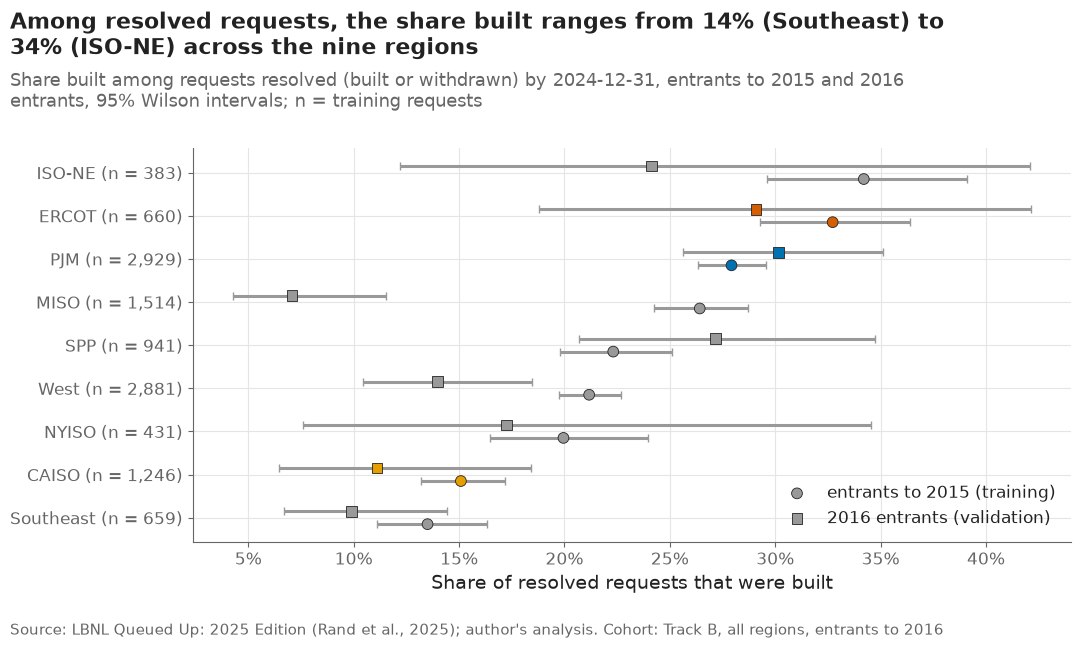

split,test,train,validation,built_train,built_validation
region,,,,,
ERCOT,87,660,55,0.327,0.291
PJM,303,2929,358,0.279,0.302
CAISO,74,1246,108,0.151,0.111
MISO,155,1514,198,0.264,0.071
SPP,167,941,151,0.223,0.272
NYISO,67,431,29,0.200,0.172
ISO-NE,51,383,29,0.342,0.241
West,338,2881,286,0.212,0.140
Southeast,292,659,232,0.135,0.099


In [2]:
requests_b = pd.read_parquet(paths.DATA_INTERIM / "trackB.parquet")
requests_b["tech"] = requests_b["type_clean"].map(plots.tech_group)
tune = requests_b[requests_b["split"] == "train"]
valid = requests_b[requests_b["split"] == "validation"]
test = requests_b[requests_b["split"] == "test"]
print(f"tuning {len(tune):,} | validation {len(valid):,} | test {len(test):,} resolved requests")

rows = []
for region in REGIONS:
    for split, part in [("train", tune), ("validation", valid)]:
        part = part[part["region"] == region]
        low, high = track_b.wilson(part["built"].sum(), len(part)) if len(part) else (np.nan, np.nan)
        rows.append({"region": region, "split": split, "n": len(part), "built_share": part["built"].mean(),
                     "low": low, "high": high})
    rows.append({"region": region, "split": "test", "n": int((test["region"] == region).sum())})
samples = pd.DataFrame(rows)
samples.to_csv(paths.RESULTS / "trackB_samples.csv", index=False)

fig, ax = plt.subplots()
order = samples[samples["split"] == "train"].sort_values("built_share")["region"].tolist()
for offset, split, marker in [(-0.15, "train", "o"), (0.15, "validation", "s")]:
    part = samples[samples["split"] == split].set_index("region").loc[order]
    y = np.arange(len(order)) + offset
    ax.errorbar(part["built_share"], y, xerr=[part["built_share"] - part["low"], part["high"] - part["built_share"]],
                fmt="none", color="#999999", capsize=3)
    ax.scatter(part["built_share"], y, marker=marker, s=60, zorder=3,
               color=[region_color(r) for r in order], edgecolors=plots.INK, linewidths=0.6,
               label="entrants to 2015 (training)" if split == "train" else "2016 entrants (validation)")
ax.set_yticks(np.arange(len(order)), [f"{r} (n = {samples[(samples['region'] == r) & (samples['split'] == 'train')]['n'].iloc[0]:,})"
                                      for r in order])
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of resolved requests that were built")
ax.legend(loc="lower right")
train_rates = samples[samples["split"] == "train"].set_index("region")["built_share"]
plots.finish(fig,
             f"Among resolved requests, the share built ranges from {train_rates.min():.0%} ({train_rates.idxmin()}) to "
             f"{train_rates.max():.0%} ({train_rates.idxmax()}) across the nine regions",
             "Share built among requests resolved (built or withdrawn) by 2024-12-31, entrants to 2015 and 2016 entrants, "
             "95% Wilson intervals; n = training requests",
             "Track B, all regions, entrants to 2016")
save(fig, "07_01_built_share_by_region", "Share built among resolved requests by region, training and validation cohorts.")
plt.show()
samples.pivot(index="region", columns="split", values="n").reindex(REGIONS).join(
    samples[samples["split"] != "test"].pivot(index="region", columns="split", values="built_share").add_prefix("built_")).round(3)

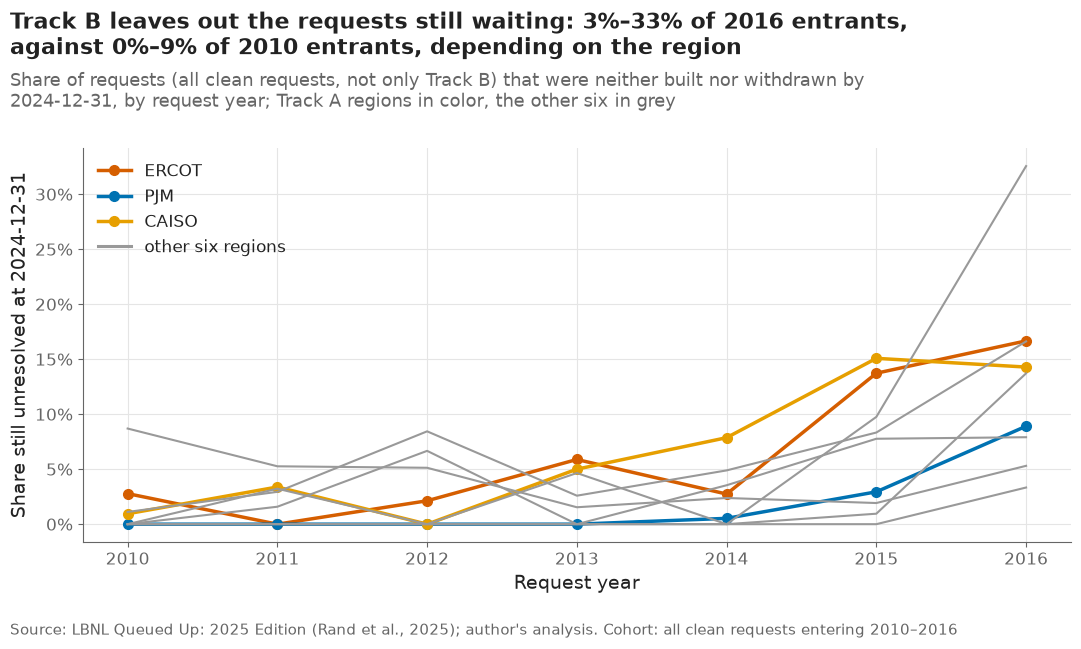

region,ERCOT,PJM,CAISO,MISO,SPP,NYISO,ISO-NE,West,Southeast
q_year,,,,,,,,,
2010,0.028,0.000,0.009,0.000,0.000,0.000,0.000,0.011,0.087
2011,0.000,0.000,0.034,0.016,0.032,0.000,0.000,0.029,0.053
2012,0.021,0.000,0.000,0.067,0.000,0.000,0.000,0.084,0.051
2013,0.059,0.000,0.050,0.000,0.047,0.000,0.000,0.026,0.015
2014,0.027,0.005,0.079,0.035,0.000,0.000,0.000,0.049,0.024
2015,0.137,0.029,0.151,0.078,0.010,0.098,0.000,0.083,0.019
2016,0.167,0.089,0.143,0.079,0.137,0.326,0.033,0.166,0.053


In [3]:
events_all = pd.read_parquet(paths.DATA_INTERIM / "queue_events.parquet")
recent = events_all[events_all["q_year"].between(2010, config.VALIDATION_YEAR)]
unresolved = recent.assign(unresolved=~recent["q_status"].isin(["operational", "withdrawn"])).groupby(
    ["q_year", "region"])["unresolved"].mean().unstack().reindex(columns=REGIONS)
fig, ax = plt.subplots()
for region in REGIONS:
    ax.plot(unresolved.index, unresolved[region], color=region_color(region),
            linewidth=2.5 if region in config.TRACK_A_REGIONS else 1.5,
            marker="o" if region in config.TRACK_A_REGIONS else None,
            label=region if region in config.TRACK_A_REGIONS else None)
ax.plot([], [], color=config.OTHER_REGION_COLOR, label="other six regions")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Request year")
ax.set_ylabel("Share still unresolved at 2024-12-31")
ax.legend(loc="upper left")
plots.finish(fig,
             f"Track B leaves out the requests still waiting: {unresolved.loc[config.VALIDATION_YEAR].min():.0%}–"
             f"{unresolved.loc[config.VALIDATION_YEAR].max():.0%} of 2016 entrants, against "
             f"{unresolved.loc[2010].min():.0%}–{unresolved.loc[2010].max():.0%} of 2010 entrants, depending on the region",
             "Share of requests (all clean requests, not only Track B) that were neither built nor withdrawn by 2024-12-31, "
             "by request year; Track A regions in color, the other six in grey",
             "all clean requests entering 2010–2016")
save(fig, "07_02_unresolved_share", "Share of requests still unresolved at the end of 2024, by request year and region.")
plt.show()
unresolved.round(3)

**Reading this.** Track B has 11,644 resolved requests for tuning (entrants to 2015), 1,446 for validation (2016) and 1,534 for testing (2017). Among the training requests the share built runs from 13.5% (Southeast) and 15.1% (CAISO) to 32.7% (ERCOT) and 34.2% (ISO-NE). The 2016 cohort is not a copy of the past: MISO's 2016 entrants were built 7.1% of the time against 26.4% for its earlier entrants, and West's 14.0% against 21.2%. The second chart shows what "resolved" leaves out: 3.3% (ISO-NE) to 32.6% (NYISO) of 2016 entrants were still waiting at the end of 2024, against at most 8.7% of 2010 entrants. Those waiting requests are the slow ones, so the later the cohort, the more Track B's built share reflects requests that resolved quickly — a selection that grows into the 2017 test cohort and that notebook 08 must state when it reports Track B results.

## 2. The benchmark: region × technology base rates

The share built among training requests of the same region and technology
(cells with fewer than 50 requests use the region's share). This is the
number an analyst would quote today, and the one the models must beat.

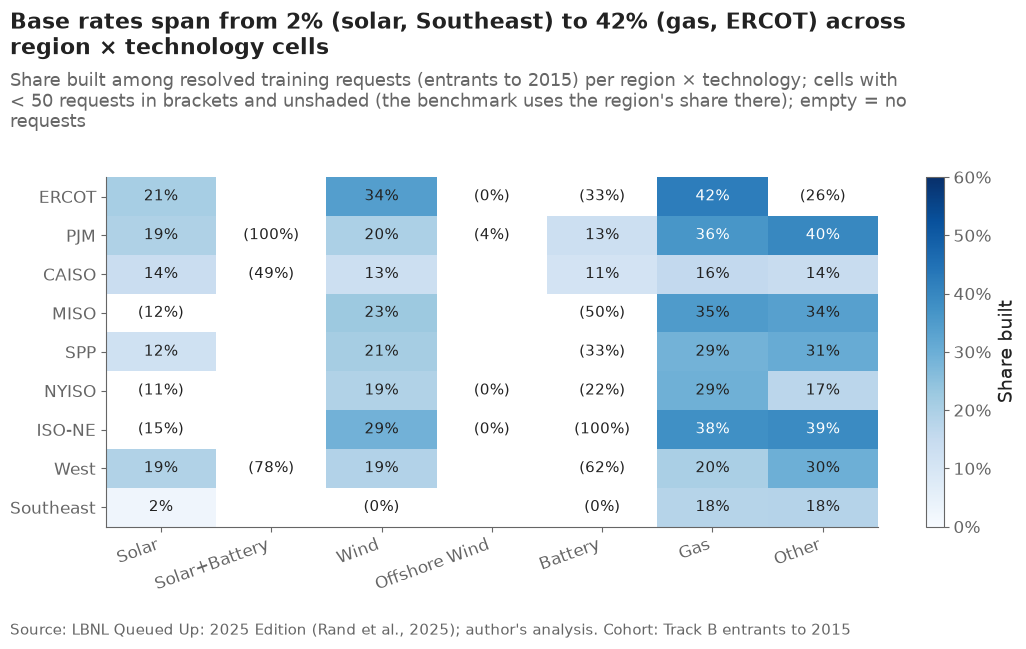

tech,Solar,Solar+Battery,Wind,Offshore Wind,Battery,Gas,Other
region,,,,,,,
ERCOT,0.208,NaN,0.341,0.000,0.333,0.420,0.262
PJM,0.193,1.000,0.198,0.043,0.130,0.361,0.398
CAISO,0.138,0.488,0.129,NaN,0.109,0.157,0.144
MISO,0.122,NaN,0.227,NaN,0.500,0.349,0.337
SPP,0.120,NaN,0.210,NaN,0.333,0.288,0.306
NYISO,0.107,NaN,0.189,0.000,0.222,0.295,0.170
ISO-NE,0.154,NaN,0.288,0.000,1.000,0.379,0.390
West,0.189,0.778,0.185,NaN,0.625,0.203,0.295
Southeast,0.024,NaN,0.000,NaN,0.000,0.179,0.182


In [4]:
cells = tune.groupby(["region", "tech"])["built"].agg(["mean", "size"]).reset_index()
cells.columns = ["region", "tech", "built_share", "n"]
cells.to_csv(paths.RESULTS / "trackB_base_rates.csv", index=False)
grid = cells.pivot(index="region", columns="tech", values="built_share").reindex(index=REGIONS, columns=discrete_time.TECH_LEVELS)
counts = cells.pivot(index="region", columns="tech", values="n").reindex(index=REGIONS, columns=discrete_time.TECH_LEVELS)
fig, ax = plt.subplots()
shown = grid.where(counts >= 50)
image = ax.imshow(shown.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=0.6, aspect="auto")
for i in range(len(REGIONS)):
    for j in range(len(discrete_time.TECH_LEVELS)):
        value, n = grid.iloc[i, j], counts.iloc[i, j]
        if pd.notna(value):
            text = f"{value:.0%}" if n >= 50 else f"({value:.0%})"
            ax.text(j, i, text, ha="center", va="center", fontsize=10.5,
                    color="white" if (n >= 50 and value > 0.35) else plots.INK)
ax.set_xticks(range(len(discrete_time.TECH_LEVELS)), discrete_time.TECH_LEVELS, rotation=20, ha="right")
ax.set_yticks(range(len(REGIONS)), REGIONS)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Share built", format=lambda x, _: f"{x:.0%}")
best = cells[cells["n"] >= 50].sort_values("built_share")
plots.finish(fig,
             f"Base rates span from {best['built_share'].iloc[0]:.0%} ({best['tech'].iloc[0].lower()}, {best['region'].iloc[0]}) "
             f"to {best['built_share'].iloc[-1]:.0%} ({best['tech'].iloc[-1].lower()}, {best['region'].iloc[-1]}) across "
             "region × technology cells",
             "Share built among resolved training requests (entrants to 2015) per region × technology; cells with < 50 requests "
             "in brackets and unshaded (the benchmark uses the region's share there); empty = no requests",
             "Track B entrants to 2015")
save(fig, "07_03_base_rates", "Region × technology share built among resolved training requests (the Track B benchmark).")
plt.show()
grid.round(3)

**Reading this.** The benchmark already knows a lot: gas is the most likely technology to be built in most regions (42% in ERCOT, 38% in ISO-NE, 36% in PJM, 35% in MISO) and solar the least (2% in the Southeast, 12% in MISO and SPP, 14% in CAISO). Many cells are small — batteries, solar+battery and offshore wind have fewer than 50 resolved training requests in most regions — and fall back to the region's share. A model earns its place only if it beats these cell averages.

## 3. Tuning

Five stratified folds on the tuning requests; inside each fold the state is
encoded on the fitting part only. The logistic regression's ridge strength
is chosen by mean cross-validated log loss. For LightGBM, every tree
setting is also run on the 2016 cohort, and — as in notebook 06 (decision
#27) — the setting and round count with the lowest 2016 log loss are kept,
because the 2016 cohort lies ahead in time of every fitting row.

no-information log loss 0.5464; logit C = 0.1, CV log loss 0.5032
LightGBM chosen on 2016: {'num_leaves': 4, 'min_data_in_leaf': 20}, 243 rounds, 2016 log loss 0.4540; CV's choice 64/20 scores 0.4852 on 2016
Spearman correlation of the 18 settings' CV and 2016 log losses: -0.85


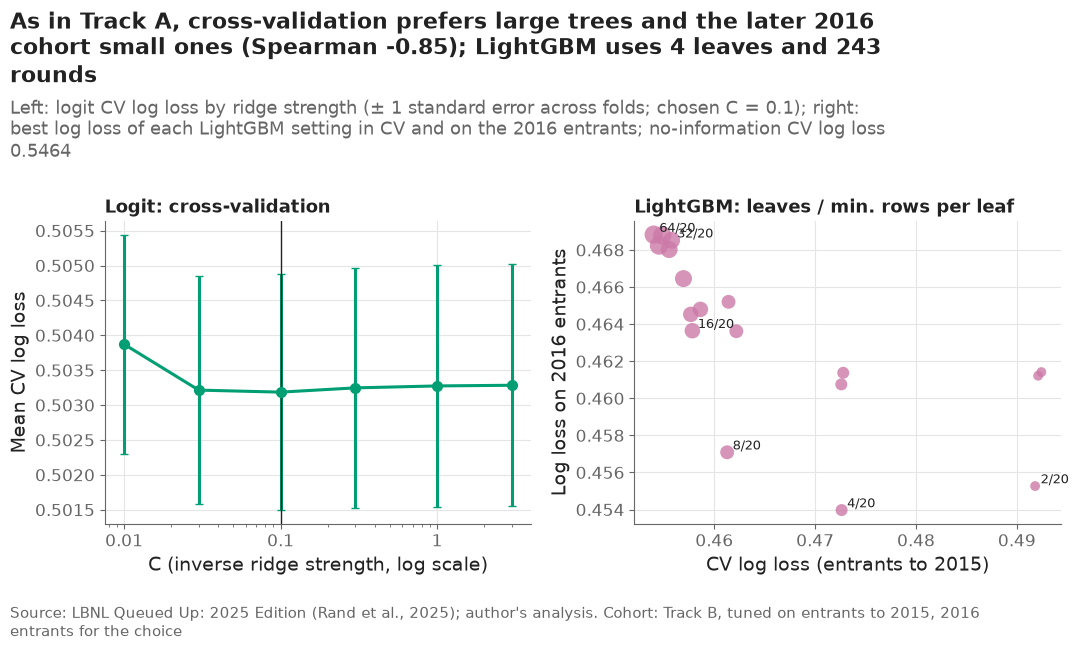

,num_leaves,min_data_in_leaf,cv_rounds,cv_log_loss,valid_rounds,valid_log_loss
3,4,20,799,0.4726,243,0.4540
0,2,20,799,0.4918,524,0.4553
6,8,20,800,0.4613,217,0.4571
5,4,100,800,0.4726,53,0.4608
1,2,50,799,0.4921,792,0.4612
4,4,50,800,0.4728,53,0.4614
2,2,100,799,0.4924,123,0.4614
7,8,50,766,0.4622,64,0.4636
9,16,20,536,0.4578,52,0.4636
11,16,100,567,0.4577,36,0.4645


In [5]:
folds = list(StratifiedKFold(5, shuffle=True, random_state=0).split(tune, tune["built"]))
fold_data = [track_b.encode_state(tune.iloc[fit_idx], [tune.iloc[held_idx]]) for fit_idx, held_idx in folds]
null_loss = np.mean([log_loss(held["built"], np.full(len(held), fit["built"].mean())) for fit, held in fold_data])
logit_rows = []
for C in LOGIT_C:
    for i, (fit, held) in enumerate(fold_data):
        model = discrete_time.fit_logit(track_b.logit_design(fit), fit["built"], C)
        logit_rows.append({"C": C, "fold": i, "log_loss": log_loss(held["built"], model.predict_proba(track_b.logit_design(held))[:, 1])})
logit_cv = pd.DataFrame(logit_rows)
logit_cv.to_csv(paths.RESULTS / "trackB_cv_logit.csv", index=False)
logit_mean = logit_cv.groupby("C")["log_loss"].agg(["mean", "std"])
LOGIT_C_BEST = float(logit_mean["mean"].idxmin())

tune_enc, valid_enc, test_enc = track_b.encode_state(tune, [valid, test])
cv_curves, valid_curves = {}, {}
for params in LGBM_GRID:
    key = (params["num_leaves"], params["min_data_in_leaf"])
    fold_curves = []
    for fit, held in fold_data:
        record = {}
        track_b.fit_lgbm(track_b.lgbm_design(fit), fit["built"], params, ROUNDS,
                         valid=(track_b.lgbm_design(held), held["built"]), record=record)
        fold_curves.append(record["valid"]["binary_logloss"])
    cv_curves[key] = np.mean(fold_curves, axis=0)
    record = {}
    track_b.fit_lgbm(track_b.lgbm_design(tune_enc), tune_enc["built"], params, ROUNDS,
                     valid=(track_b.lgbm_design(valid_enc), valid_enc["built"]), record=record)
    valid_curves[key] = np.array(record["valid"]["binary_logloss"])
lgbm_cv = pd.DataFrame([{"num_leaves": k[0], "min_data_in_leaf": k[1],
                         "cv_rounds": int(cv_curves[k].argmin() + 1), "cv_log_loss": float(cv_curves[k].min()),
                         "valid_rounds": int(valid_curves[k].argmin() + 1), "valid_log_loss": float(valid_curves[k].min())}
                        for k in cv_curves])
lgbm_cv.to_csv(paths.RESULTS / "trackB_cv_lgbm.csv", index=False)
chosen = lgbm_cv.loc[lgbm_cv["valid_log_loss"].idxmin()]
cv_best = lgbm_cv.loc[lgbm_cv["cv_log_loss"].idxmin()]
LGBM_PARAMS = {"num_leaves": int(chosen["num_leaves"]), "min_data_in_leaf": int(chosen["min_data_in_leaf"])}
N_ROUNDS = int(chosen["valid_rounds"])
rank_agreement = lgbm_cv[["cv_log_loss", "valid_log_loss"]].corr(method="spearman").iloc[0, 1]
print(f"no-information log loss {null_loss:.4f}; logit C = {LOGIT_C_BEST:g}, CV log loss {logit_mean['mean'].min():.4f}")
print(f"LightGBM chosen on 2016: {LGBM_PARAMS}, {N_ROUNDS} rounds, 2016 log loss {chosen['valid_log_loss']:.4f}; "
      f"CV's choice {int(cv_best['num_leaves'])}/{int(cv_best['min_data_in_leaf'])} scores "
      f"{valid_curves[(int(cv_best['num_leaves']), int(cv_best['min_data_in_leaf']))][int(cv_best['cv_rounds']) - 1]:.4f} on 2016")
print(f"Spearman correlation of the {len(lgbm_cv)} settings' CV and 2016 log losses: {rank_agreement:.2f}")
tuning = {"logit_C": LOGIT_C_BEST, "logit_cv_log_loss": float(logit_mean["mean"].min()), "lgbm": {**LGBM_PARAMS, "rounds": N_ROUNDS},
          "lgbm_valid_log_loss": float(chosen["valid_log_loss"]), "spearman_cv_vs_2016": float(rank_agreement)}
(paths.RESULTS / "trackB_tuning.json").write_text(json.dumps(tuning, indent=2), encoding="utf-8")

fig, axes = plt.subplots(1, 2)
ax = axes[0]
ax.errorbar(logit_mean.index, logit_mean["mean"], yerr=logit_mean["std"] / np.sqrt(len(folds)), color=MODEL_COLORS["logit"],
            marker="o", capsize=3)
ax.axvline(LOGIT_C_BEST, color=plots.INK, linewidth=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
ax.set_xlabel("C (inverse ridge strength, log scale)")
ax.set_ylabel("Mean CV log loss")
ax.set_title("Logit: cross-validation", fontsize=13)
ax = axes[1]
ax.scatter(lgbm_cv["cv_log_loss"], lgbm_cv["valid_log_loss"], s=25 * np.log2(lgbm_cv["num_leaves"] * 2),
           color=MODEL_COLORS["lgbm"], alpha=0.8, edgecolors="white")
for r in lgbm_cv.itertuples():
    if r.Index in (chosen.name, cv_best.name) or r.min_data_in_leaf == 20:  # label one row per tree size, plus the two choices
        ax.annotate(f"{r.num_leaves}/{r.min_data_in_leaf}", (r.cv_log_loss, r.valid_log_loss), xytext=(4, 2),
                    textcoords="offset points", fontsize=9)
ax.set_xlabel("CV log loss (entrants to 2015)")
ax.set_ylabel("Log loss on 2016 entrants")
ax.set_title("LightGBM: leaves / min. rows per leaf", fontsize=13)
plots.finish(fig,
             f"As in Track A, cross-validation prefers large trees and the later 2016 cohort small ones (Spearman "
             f"{rank_agreement:.2f}); LightGBM uses {LGBM_PARAMS['num_leaves']} leaves and {N_ROUNDS} rounds",
             f"Left: logit CV log loss by ridge strength (± 1 standard error across folds; chosen C = {LOGIT_C_BEST:g}); right: best "
             f"log loss of each LightGBM setting in CV and on the 2016 entrants; no-information CV log loss {null_loss:.4f}",
             "Track B, tuned on entrants to 2015, 2016 entrants for the choice")
save(fig, "07_04_tuning", "Track B tuning: logit ridge strength and LightGBM settings in cross-validation and on the 2016 cohort.")
plt.show()
lgbm_cv.sort_values("valid_log_loss").round(4)

**Reading this.** The logistic regression is insensitive to its penalty (CV log loss 0.5032–0.5039 across C from 0.01 to 3; no information 0.5464); C = 0.1 is used. LightGBM repeats Track A's pattern: grouped cross-validation favours large trees, while the later 2016 cohort favours small ones (Spearman −0.85 between the 18 settings' two log losses). The setting chosen on 2016, 4 leaves and at least 20 requests per leaf after 243 rounds, scores 0.4540 there, against 0.4852 for the CV's choice of 64 leaves. Four-leaf trees can represent only low-order interactions, so on this sample the boosted model is close to an additive one; the 2-leaf (purely additive) setting scores 0.4553.

## 4. The 2016 cohort: discrimination and calibration

The models fitted on entrants to 2015 score the 2016 cohort. AUC measures
ranking (0.5 = coin flip), Brier the squared error of the probabilities
(lower is better); intervals from 200 bootstrap resamples. The calibrated
versions are scored **cross-fitted**: the isotonic map applied to each half
of the cohort was fitted on the other half, so the calibration step does not
grade itself. The final map (used for the 2017 predictions) is fitted on the
whole cohort.

observed share built, 2016 cohort: 0.184 (n = 1,446)


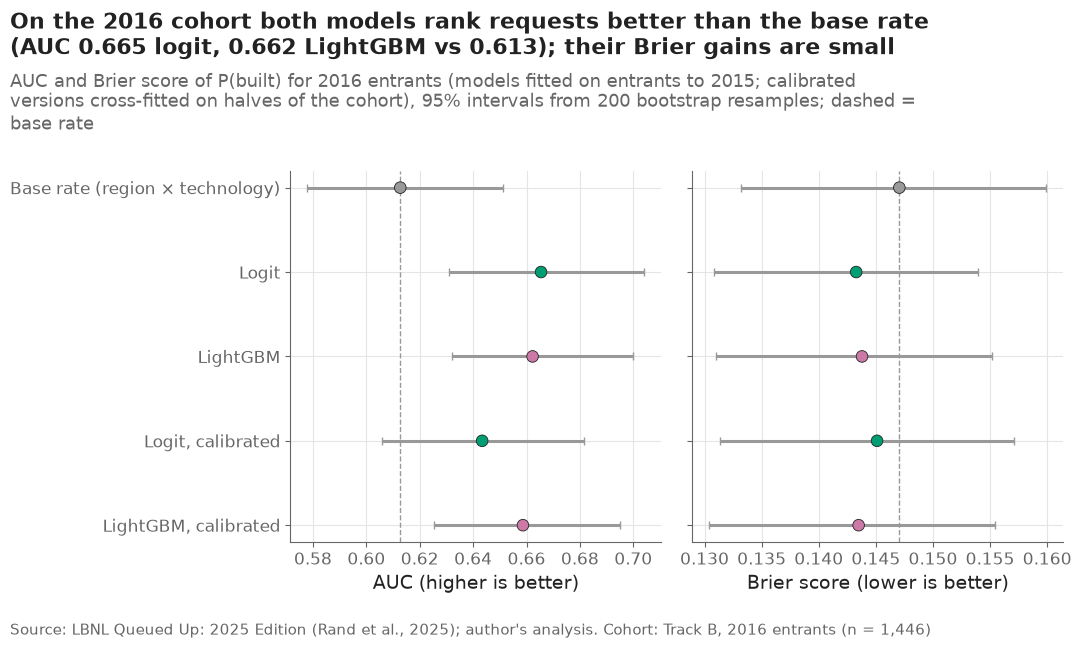

,model,auc,auc_low,auc_high,brier,brier_low,brier_high,mean_predicted
0,baseline,0.6127,0.5778,0.6510,0.1471,0.1332,0.1599,0.1895
1,logit,0.6654,0.6309,0.7041,0.1433,0.1309,0.1540,0.2110
2,lgbm,0.6623,0.6320,0.6998,0.1438,0.1310,0.1551,0.1993
3,logit_cal,0.6434,0.6058,0.6815,0.1451,0.1313,0.1571,0.1829
4,lgbm_cal,0.6586,0.6255,0.6950,0.1435,0.1304,0.1554,0.1828


In [6]:
logit = discrete_time.fit_logit(track_b.logit_design(tune_enc), tune_enc["built"], LOGIT_C_BEST)
lgbm = track_b.fit_lgbm(track_b.lgbm_design(tune_enc), tune_enc["built"], LGBM_PARAMS, N_ROUNDS)
raw_valid = {"logit": logit.predict_proba(track_b.logit_design(valid_enc))[:, 1],
             "lgbm": lgbm.predict(track_b.lgbm_design(valid_enc))}
y_valid = valid["built"].to_numpy()
maps = {m: track_b.isotonic(p, y_valid) for m, p in raw_valid.items()}
valid_preds = {"baseline": track_b.base_rates(tune, valid)["rate"].to_numpy(), **raw_valid,
               **{f"{m}_cal": track_b.cross_fit_isotonic(p, y_valid) for m, p in raw_valid.items()}}
metrics = bootstrap_metrics(y_valid, valid_preds)
metrics["mean_predicted"] = [np.mean(valid_preds[m]) for m in metrics["model"]]
metrics.to_csv(paths.RESULTS / "trackB_validation.csv", index=False)
print(f"observed share built, 2016 cohort: {y_valid.mean():.3f} (n = {len(y_valid):,})")

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, (metric, label) in zip(axes, [("auc", "AUC (higher is better)"), ("brier", "Brier score (lower is better)")]):
    y = np.arange(len(metrics))[::-1]
    ax.errorbar(metrics[metric], y, xerr=[metrics[metric] - metrics[f"{metric}_low"], metrics[f"{metric}_high"] - metrics[metric]],
                fmt="none", color="#999999", capsize=3)
    ax.scatter(metrics[metric], y, s=70, zorder=3, color=[MODEL_COLORS[m] for m in metrics["model"]],
               marker="o", edgecolors=plots.INK, linewidths=0.6)
    ax.axvline(metrics.loc[metrics["model"] == "baseline", metric].iloc[0], color="#999999", linestyle="--", linewidth=1)
    ax.set_xlabel(label)
axes[0].set_yticks(np.arange(len(metrics))[::-1], [MODEL_LABELS[m] for m in metrics["model"]])
m = metrics.set_index("model")
plots.finish(fig,
             f"On the 2016 cohort both models rank requests better than the base rate (AUC {m.loc['logit', 'auc']:.3f} logit, "
             f"{m.loc['lgbm', 'auc']:.3f} LightGBM vs {m.loc['baseline', 'auc']:.3f}); their Brier gains are small",
             "AUC and Brier score of P(built) for 2016 entrants (models fitted on entrants to 2015; calibrated versions "
             "cross-fitted on halves of the cohort), 95% intervals from 200 bootstrap resamples; dashed = base rate",
             f"Track B, {config.VALIDATION_YEAR} entrants (n = {len(y_valid):,})")
save(fig, "07_05_validation_metrics", "AUC and Brier score of the Track B models and the base rate on the 2016 cohort.")
plt.show()
metrics.round(4)

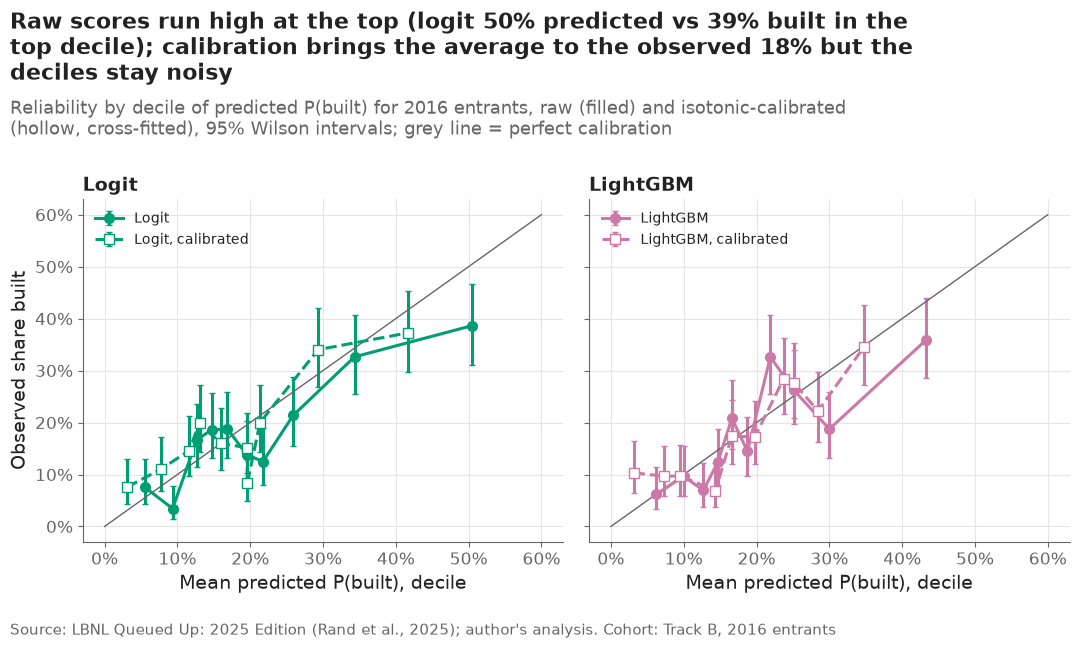

,bin,predicted,observed,n,model
0,0,0.055,0.076,145,logit
1,1,0.093,0.034,145,logit
2,2,0.126,0.167,144,logit
3,3,0.147,0.186,145,logit
4,4,0.169,0.188,144,logit
5,5,0.195,0.138,145,logit
6,6,0.218,0.125,144,logit
7,7,0.259,0.214,145,logit
8,8,0.343,0.326,144,logit
9,9,0.504,0.386,145,logit


In [7]:
deciles = []
fig, axes = plt.subplots(1, 2, sharey=True, sharex=True)
for ax, model in zip(axes, ["logit", "lgbm"]):
    for version, style in [(model, dict(marker="o", linestyle="-")), (f"{model}_cal", dict(marker="s", linestyle="--"))]:
        p = valid_preds[version]
        bins = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)  # rank first: tied calibrated values still split into tenths
        table = pd.DataFrame({"p": p, "y": y_valid, "bin": bins}).groupby("bin").agg(predicted=("p", "mean"), observed=("y", "mean"),
                                                                                     n=("y", "size"))
        low, high = track_b.wilson(table["observed"] * table["n"], table["n"])
        ax.errorbar(table["predicted"], table["observed"], yerr=[table["observed"] - low, high - table["observed"]],
                    color=MODEL_COLORS[model], capsize=2, label=MODEL_LABELS[version],
                    markerfacecolor="white" if version.endswith("cal") else MODEL_COLORS[model], **style)
        deciles.append(table.assign(model=version).reset_index())
    ax.plot([0, 0.6], [0, 0.6], color=plots.MUTED, linewidth=1)
    ax.set_title(MODEL_LABELS[model])
    ax.set_xlabel("Mean predicted P(built), decile")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
    ax.legend(loc="upper left", fontsize=10)
axes[0].set_ylabel("Observed share built")
calibration = pd.concat(deciles, ignore_index=True)
calibration.to_csv(paths.RESULTS / "trackB_calibration.csv", index=False)
top = calibration.groupby("model").apply(lambda t: t.sort_values("predicted").iloc[-1], include_groups=False)
plots.finish(fig,
             f"Raw scores run high at the top (logit {top.loc['logit', 'predicted']:.0%} predicted vs "
             f"{top.loc['logit', 'observed']:.0%} built in the top decile); calibration brings the average to the observed "
             f"{y_valid.mean():.0%} but the deciles stay noisy",
             "Reliability by decile of predicted P(built) for 2016 entrants, raw (filled) and isotonic-calibrated (hollow, "
             "cross-fitted), 95% Wilson intervals; grey line = perfect calibration",
             f"Track B, {config.VALIDATION_YEAR} entrants")
save(fig, "07_06_reliability_2016", "Reliability diagrams of the Track B models on the 2016 cohort, raw and isotonic-calibrated.")
plt.show()
calibration.round(3)

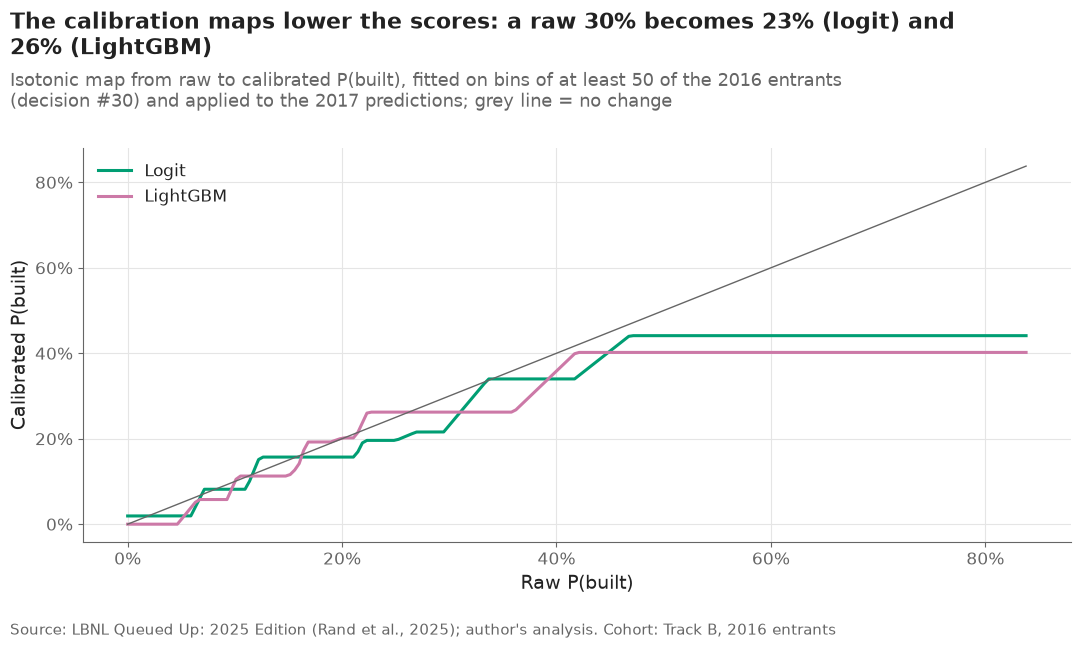

,logit,lgbm
0.1,0.082,0.099
0.2,0.157,0.202
0.3,0.231,0.262
0.4,0.340,0.358
0.5,0.441,0.402


In [8]:
fig, ax = plt.subplots()
grid_p = np.linspace(0, max(valid_preds["logit"].max(), valid_preds["lgbm"].max()), 200)
for model in ["logit", "lgbm"]:
    ax.plot(grid_p, maps[model].predict(grid_p), color=MODEL_COLORS[model], label=MODEL_LABELS[model])
ax.plot([0, grid_p.max()], [0, grid_p.max()], color=plots.MUTED, linewidth=1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Raw P(built)")
ax.set_ylabel("Calibrated P(built)")
ax.legend(loc="upper left")
at = {m: float(maps[m].predict([0.3])[0]) for m in maps}
plots.finish(fig,
             f"The calibration maps lower the scores: a raw 30% becomes {at['logit']:.0%} (logit) and {at['lgbm']:.0%} (LightGBM)",
             "Isotonic map from raw to calibrated P(built), fitted on bins of at least 50 of the 2016 entrants (decision #30) "
             "and applied to the 2017 predictions; grey line = no change",
             f"Track B, {config.VALIDATION_YEAR} entrants")
save(fig, "07_07_isotonic_maps", "Isotonic calibration maps of the two Track B models, fitted on the 2016 cohort.")
plt.show()
pd.DataFrame({m: maps[m].predict([0.1, 0.2, 0.3, 0.4, 0.5]) for m in maps}, index=[0.1, 0.2, 0.3, 0.4, 0.5]).round(3)

**Reading this.** On the 2016 cohort (18.4% built), both models rank requests better than the region × technology base rate: AUC 0.665 (95% interval 0.631–0.704) for the logit and 0.662 (0.632–0.700) for LightGBM, against 0.613 (0.578–0.651). The Brier scores barely differ (0.1433 and 0.1438 against 0.1471) and their intervals overlap almost entirely, so the models' gain is in ranking, not in the size of their probabilities. The raw scores run high (mean 21.1% for the logit and 19.9% for LightGBM against 18.4% observed; logit's top decile 50.4% predicted vs 38.6% built). Calibration on bins of at least 50 requests, scored cross-fitted, brings the mean to 18.3% for both, but it does not improve the scores overall: the calibrated logit is worse (Brier 0.1451, AUC 0.643) and the calibrated LightGBM about equal (0.1435, AUC 0.659). The maps lower the scores (a raw 30% becomes 23.1% for the logit and 26.2% for LightGBM) and are flat beyond the top bin, so no 2017 request receives more than 44.1% (logit) or 40.2% (LightGBM). Without the bins, isotonic regression had sent LightGBM's map to 100% above a raw score of 0.53 on the strength of nine 2016 requests, a value 29 test requests would have inherited (decision #30). The flat steps have a cost for a developer: calibrated values tie, so they rank requests more coarsely than the raw scores.

## 5. Region by region, and with each region held out

Two questions per region. **Calibration on 2016:** is the calibrated models'
mean P(built) for the region's 2016 entrants inside the 95% Wilson interval
of the share actually built? (Cross-fitted calibrated values, as above.)
**Leave one region out:** refit both models (and their isotonic maps) without
the region, then predict all its entrants to 2016 — the setting of a region
whose history the model has never seen. The benchmark there is the share
built by technology in the other regions. A region "fails" when the mean
prediction falls outside the interval of the observed share; this rule is
written here before the table is computed.

In [9]:
region_rows = []
for region in REGIONS:
    mask = (valid["region"] == region).to_numpy()
    k, n = int(y_valid[mask].sum()), int(mask.sum())
    low, high = track_b.wilson(k, n)
    row = {"region": region, "n_2016": n, "observed_2016": k / n, "low_2016": low, "high_2016": high}
    for model in ["baseline", "logit_cal", "lgbm_cal"]:
        row[f"{model}_2016"] = valid_preds[model][mask].mean()
        row[f"{model}_2016_fails"] = not (low <= row[f"{model}_2016"] <= high)
    region_rows.append(row)
by_region = pd.DataFrame(region_rows).set_index("region")

holdout = pd.concat([tune, valid])
loro_rows = []
for region in REGIONS:
    fit_t, fit_v = tune[tune["region"] != region], valid[valid["region"] != region]
    target = holdout[holdout["region"] == region]
    fit_t_enc, fit_v_enc, target_enc = track_b.encode_state(fit_t, [fit_v, target])
    lo_logit = discrete_time.fit_logit(track_b.logit_design(fit_t_enc), fit_t_enc["built"], LOGIT_C_BEST)
    lo_lgbm = track_b.fit_lgbm(track_b.lgbm_design(fit_t_enc), fit_t_enc["built"], LGBM_PARAMS, N_ROUNDS)
    preds = {}
    for model, fitted, design, predict in [
            ("logit", lo_logit, track_b.logit_design, lambda m, X: m.predict_proba(X)[:, 1]),
            ("lgbm", lo_lgbm, track_b.lgbm_design, lambda m, X: m.predict(X))]:
        cal = track_b.isotonic(predict(fitted, design(fit_v_enc)), fit_v_enc["built"])
        preds[model] = cal.predict(predict(fitted, design(target_enc)))
    preds["tech_rate"] = track_b.technology_rates(pd.concat([fit_t, fit_v]), target).to_numpy()
    y = target["built"].to_numpy()
    low, high = track_b.wilson(y.sum(), len(y))
    row = {"region": region, "n_loro": len(y), "observed_loro": y.mean(), "low_loro": low, "high_loro": high}
    for model, p in preds.items():
        row[f"{model}_loro"] = p.mean()
        row[f"{model}_loro_auc"] = roc_auc_score(y, p)
        row[f"{model}_loro_brier"] = brier_score_loss(y, p)
        row[f"{model}_loro_fails"] = not (low <= p.mean() <= high)
    loro_rows.append(row)
loro = pd.DataFrame(loro_rows).set_index("region")
by_region = by_region.join(loro)
by_region.to_csv(paths.RESULTS / "trackB_by_region.csv")
fails_2016 = [r for r in REGIONS if by_region.loc[r, ["logit_cal_2016_fails", "lgbm_cal_2016_fails"]].any()]
fails_loro = [r for r in REGIONS if by_region.loc[r, ["logit_loro_fails", "lgbm_loro_fails"]].any()]
print("regions where a calibrated model misses the 2016 interval:", fails_2016 or "none")
print("regions where a held-out model misses the observed interval:", fails_loro or "none")
by_region[["n_2016", "observed_2016", "low_2016", "high_2016", "baseline_2016", "logit_cal_2016", "lgbm_cal_2016"]].round(3)

regions where a calibrated model misses the 2016 interval: ['PJM', 'MISO', 'SPP']
regions where a held-out model misses the observed interval: ['ERCOT', 'PJM', 'CAISO', 'MISO', 'SPP', 'NYISO', 'West', 'Southeast']


,n_2016,observed_2016,low_2016,high_2016,baseline_2016,logit_cal_2016,lgbm_cal_2016
region,,,,,,,
ERCOT,55,0.291,0.188,0.421,0.279,0.219,0.275
PJM,358,0.302,0.256,0.351,0.235,0.261,0.239
CAISO,108,0.111,0.065,0.184,0.136,0.171,0.126
MISO,198,0.071,0.043,0.115,0.250,0.190,0.255
SPP,151,0.272,0.207,0.347,0.199,0.180,0.217
NYISO,29,0.172,0.076,0.345,0.203,0.159,0.132
ISO-NE,29,0.241,0.122,0.421,0.358,0.258,0.263
West,286,0.140,0.104,0.185,0.197,0.139,0.127
Southeast,232,0.099,0.067,0.144,0.033,0.102,0.081


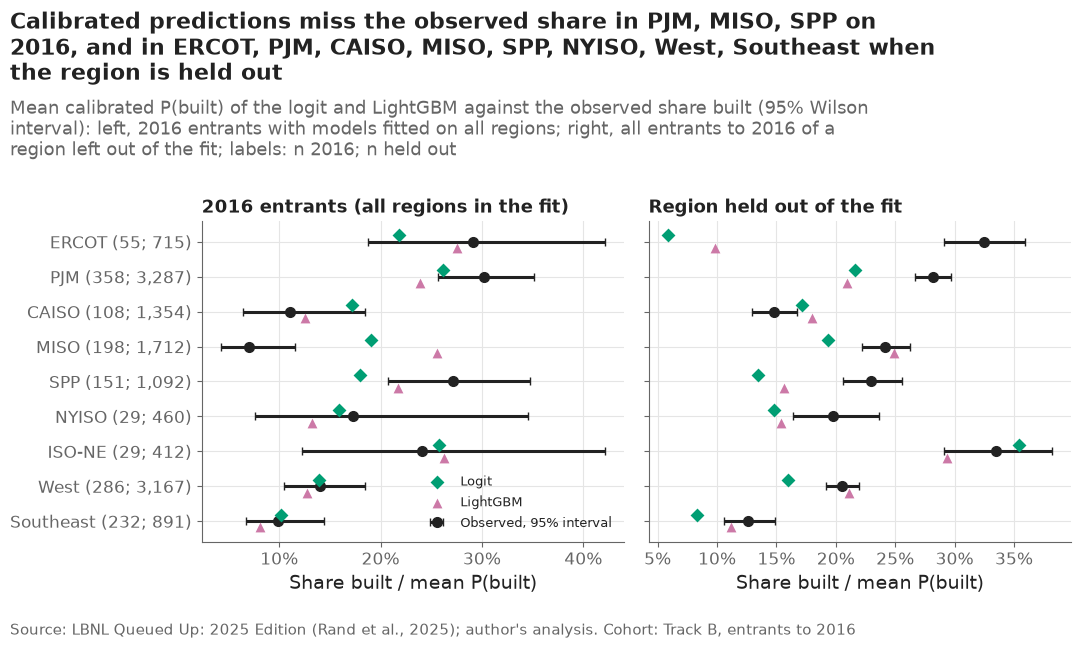

,n_loro,observed_loro,low_loro,high_loro,logit_loro,lgbm_loro,tech_rate_loro
region,,,,,,,
ERCOT,715,0.324,0.291,0.360,0.059,0.099,0.215
PJM,3287,0.282,0.267,0.297,0.217,0.210,0.212
CAISO,1354,0.148,0.130,0.168,0.172,0.180,0.228
MISO,1712,0.242,0.222,0.263,0.194,0.249,0.238
SPP,1092,0.230,0.206,0.256,0.135,0.157,0.226
NYISO,460,0.198,0.164,0.237,0.148,0.154,0.256
ISO-NE,412,0.335,0.291,0.382,0.354,0.294,0.260
West,3167,0.205,0.192,0.220,0.160,0.211,0.226
Southeast,891,0.126,0.106,0.149,0.083,0.112,0.254


In [10]:
fig, axes = plt.subplots(1, 2, sharey=True)
y = np.arange(len(REGIONS))[::-1]
for ax, (suffix, title) in zip(axes, [("2016", "2016 entrants (all regions in the fit)"), ("loro", "Region held out of the fit")]):
    observed, low, high = by_region[f"observed_{suffix}"], by_region[f"low_{suffix}"], by_region[f"high_{suffix}"]
    ax.errorbar(observed, y, xerr=[observed - low, high - observed], fmt="o", color=plots.INK, capsize=3,
                label="Observed, 95% interval")
    models = ["logit_cal", "lgbm_cal"] if suffix == "2016" else ["logit", "lgbm"]
    for model, dy, marker in zip(models, [0.18, -0.18], ["D", "^"]):
        base_model = model.replace("_cal", "")
        ax.scatter(by_region[f"{model}_{suffix}"], y + dy, marker=marker, s=50, color=MODEL_COLORS[base_model], zorder=3,
                   label=f"{MODEL_LABELS[base_model]}")
    ax.set_title(title, fontsize=13)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("Share built / mean P(built)")
axes[0].set_yticks(y, [f"{r} ({by_region.loc[r, 'n_2016']}; {by_region.loc[r, 'n_loro']:,})" for r in REGIONS])
axes[0].legend(loc="lower right", fontsize=9.5)
plots.finish(fig,
             "Calibrated predictions miss the observed share in "
             + (", ".join(fails_2016) if fails_2016 else "no region") + " on 2016, and in "
             + (", ".join(fails_loro) if fails_loro else "no region") + " when the region is held out",
             "Mean calibrated P(built) of the logit and LightGBM against the observed share built (95% Wilson interval): left, 2016 entrants with models "
             "fitted on all regions; right, all entrants to 2016 of a region left out of the fit; labels: n 2016; n held out",
             "Track B, entrants to 2016")
save(fig, "07_08_calibration_by_region", "Mean calibrated P(built) against the observed share by region, on 2016 and with the region held out.")
plt.show()
by_region[["n_loro", "observed_loro", "low_loro", "high_loro", "logit_loro", "lgbm_loro", "tech_rate_loro"]].round(3)

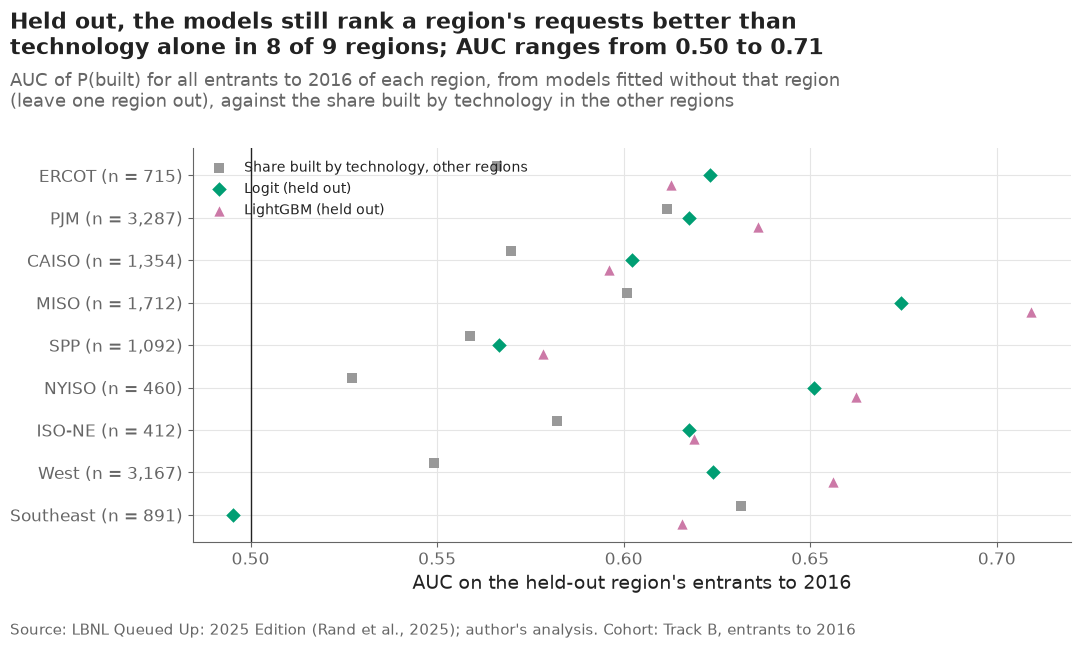

,tech_rate_loro_auc,logit_loro_auc,lgbm_loro_auc,tech_rate_loro_brier,logit_loro_brier,lgbm_loro_brier
region,,,,,,
ERCOT,0.566,0.623,0.613,0.229,0.282,0.263
PJM,0.612,0.617,0.636,0.202,0.199,0.200
CAISO,0.570,0.602,0.596,0.131,0.125,0.125
MISO,0.601,0.674,0.709,0.179,0.173,0.167
SPP,0.559,0.566,0.578,0.175,0.182,0.180
NYISO,0.527,0.651,0.662,0.162,0.155,0.153
ISO-NE,0.582,0.618,0.619,0.223,0.216,0.217
West,0.549,0.624,0.656,0.163,0.160,0.156
Southeast,0.631,0.495,0.616,0.123,0.114,0.109


In [11]:
fig, ax = plt.subplots()
y = np.arange(len(REGIONS))[::-1]
for model, dy, marker in [("tech_rate", 0.22, "s"), ("logit", 0, "D"), ("lgbm", -0.22, "^")]:
    color = "#999999" if model == "tech_rate" else MODEL_COLORS[model]
    label = "Share built by technology, other regions" if model == "tech_rate" else f"{MODEL_LABELS[model]} (held out)"
    ax.scatter(by_region[f"{model}_loro_auc"], y + dy, marker=marker, s=55, color=color, label=label, zorder=3)
ax.axvline(0.5, color=plots.INK, linewidth=1)
ax.set_yticks(y, [f"{r} (n = {by_region.loc[r, 'n_loro']:,})" for r in REGIONS])
ax.set_xlabel("AUC on the held-out region's entrants to 2016")
ax.legend(loc="upper left", fontsize=10)
gain = (by_region[["logit_loro_auc", "lgbm_loro_auc"]].max(axis=1) - by_region["tech_rate_loro_auc"])
plots.finish(fig,
             f"Held out, the models still rank a region's requests better than technology alone in {int((gain > 0).sum())} of 9 "
             f"regions; AUC ranges from {by_region[['logit_loro_auc', 'lgbm_loro_auc']].min().min():.2f} to "
             f"{by_region[['logit_loro_auc', 'lgbm_loro_auc']].max().max():.2f}",
             "AUC of P(built) for all entrants to 2016 of each region, from models fitted without that region (leave one region "
             "out), against the share built by technology in the other regions",
             "Track B, entrants to 2016")
save(fig, "07_09_loro_auc", "Leave-one-region-out AUC of the Track B models against a technology-only benchmark.")
plt.show()
by_region[["tech_rate_loro_auc", "logit_loro_auc", "lgbm_loro_auc", "tech_rate_loro_brier", "logit_loro_brier", "lgbm_loro_brier"]].round(3)

**Reading this.** Region by region the picture is mixed. On the 2016 cohort, the calibrated models miss the observed share in three regions: MISO (7.1% built; both models 19.0% and 25.5% — the base rate, 25.0%, misses too), SPP (27.2% built; logit 18.0% below the interval) and PJM (30.2% built; LightGBM 23.9% below it). When a region is held out entirely, the models miss its level in 8 of 9 regions, ISO-NE being the exception: a model cannot learn a region's own propensity without seeing it. The worst case is ERCOT, predicted at 5.9% (logit) and 9.9% (LightGBM) against 32.4% built — below even the technology-only benchmark (21.5%). The likely reason is a data artefact rather than a modelling one: ERCOT's GW waiting at entry is inflated by its stamped withdrawals (notebook 06, figure 06_02), and more GW waiting lowers the odds of being built (0.663 per log unit), so ERCOT looks far more congested than any queue the model was trained on. Ranking transfers better than levels: held out, the models' AUC beats the technology-only benchmark in 8 of 9 regions (e.g. MISO 0.709 for LightGBM vs 0.601; NYISO 0.662 vs 0.527), the exception being the Southeast (logit 0.495, LightGBM 0.616 vs 0.631). For a developer in a region outside the training data the message is: use the model to rank, not as a probability.

## 6. What the models say

The logistic regression's odds ratios (P(built) against withdrawn) with 95%
intervals from 200 bootstrap resamples of requests, and LightGBM's split-gain
shares.

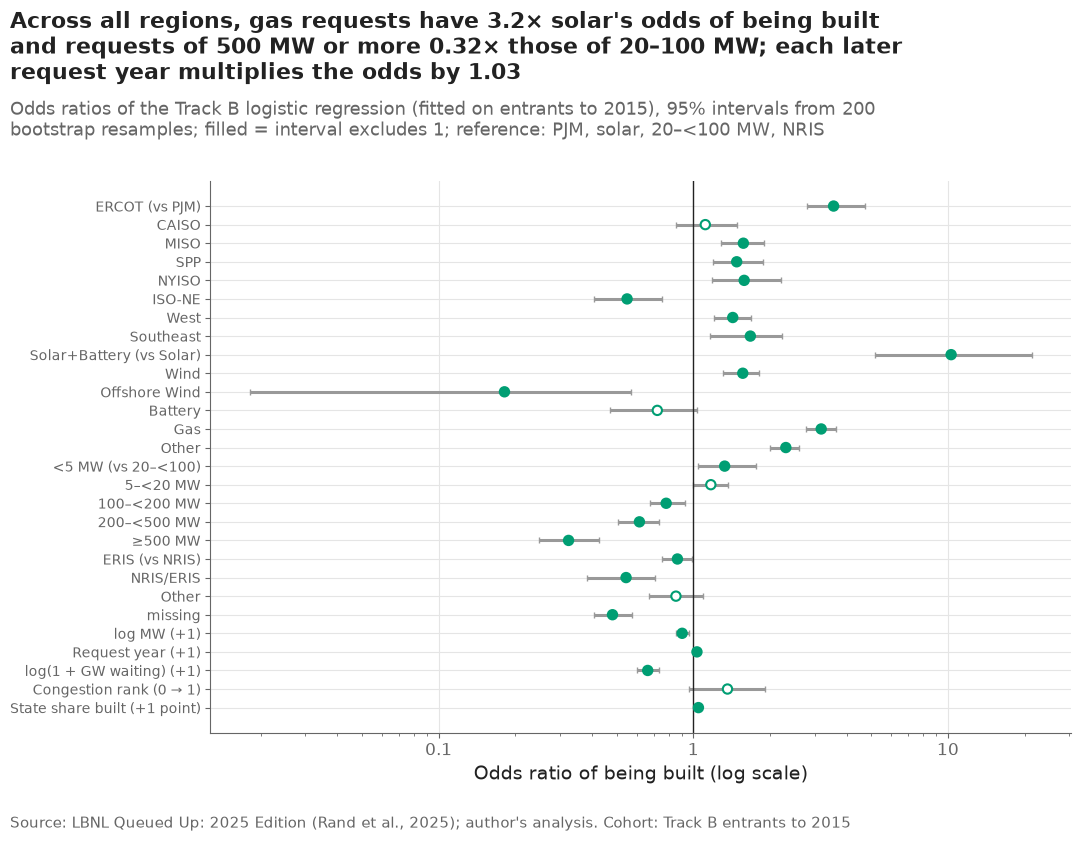

,odds_ratio,ci_low,ci_high
label,,,
ERCOT (vs PJM),3.557,2.784,4.721
CAISO,1.115,0.853,1.481
MISO,1.573,1.286,1.899
SPP,1.481,1.200,1.886
NYISO,1.585,1.188,2.210
ISO-NE,0.550,0.409,0.753
West,1.429,1.204,1.681
Southeast,1.676,1.169,2.237
Solar+Battery (vs Solar),10.293,5.155,21.364


In [12]:
X_tune = track_b.logit_design(tune_enc)
scale = logit[0].scale_
point = pd.Series(logit[-1].coef_[0] / scale, index=X_tune.columns)
rng = np.random.default_rng(11)
draws = []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(X_tune), len(X_tune))
    model = discrete_time.fit_logit(X_tune.iloc[idx], tune_enc["built"].iloc[idx], LOGIT_C_BEST)
    draws.append(model[-1].coef_[0] / model[0].scale_)
draws = np.array(draws)
units = {"state_rate": 0.01}
odds = pd.DataFrame({"term": X_tune.columns, "odds_ratio": np.exp(point.to_numpy() * [units.get(c, 1) for c in X_tune.columns]),
                     "ci_low": np.exp(np.quantile(draws, 0.025, axis=0) * [units.get(c, 1) for c in X_tune.columns]),
                     "ci_high": np.exp(np.quantile(draws, 0.975, axis=0) * [units.get(c, 1) for c in X_tune.columns])})
odds.to_csv(paths.RESULTS / "trackB_odds_ratios.csv", index=False)

LABELS = {**{f"region_{r}": f"{r} (vs PJM)" if r == "ERCOT" else r for r in REGIONS},
          **{f"tech_{t}": (f"{t} (vs Solar)" if t == "Solar+Battery" else t) for t in discrete_time.TECH_LEVELS},
          **{f"size_{s}": (f"{s} MW (vs 20–<100)" if s == "<5" else f"{s} MW") for s in config.SIZE_LABELS},
          **{f"service_{s}": (f"{s} (vs NRIS)" if s == "ERIS" else s) for s in track_b.SERVICE_LEVELS},
          "log_mw": "log MW (+1)", "q_year": "Request year (+1)", "log_congestion_gw": "log(1 + GW waiting) (+1)",
          "congestion_rank": "Congestion rank (0 → 1)", "state_rate": "State share built (+1 point)"}
fig, ax = plt.subplots(figsize=(11, 8.5))
y = np.arange(len(odds))[::-1]
significant = (odds["ci_low"] > 1) | (odds["ci_high"] < 1)
ax.errorbar(odds["odds_ratio"], y, xerr=[odds["odds_ratio"] - odds["ci_low"], odds["ci_high"] - odds["odds_ratio"]],
            fmt="none", color="#999999", capsize=2)
ax.scatter(odds["odds_ratio"], y, s=45, zorder=3, color=np.where(significant, MODEL_COLORS["logit"], "white"),
           edgecolors=MODEL_COLORS["logit"], linewidths=1.5)
ax.axvline(1, color=plots.INK, linewidth=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
ax.set_yticks(y, [LABELS.get(t, t) for t in odds["term"]], fontsize=10)
ax.set_xlabel("Odds ratio of being built (log scale)")
o = odds.set_index("term")["odds_ratio"]
plots.finish(fig,
             f"Across all regions, gas requests have {o['tech_Gas']:.1f}× solar's odds of being built and requests of 500 MW or "
             f"more {o['size_≥500']:.2f}× those of 20–100 MW; each later request year multiplies the odds by {o['q_year']:.2f}",
             "Odds ratios of the Track B logistic regression (fitted on entrants to 2015), 95% intervals from 200 bootstrap "
             "resamples; filled = interval excludes 1; reference: PJM, solar, 20–<100 MW, NRIS",
             "Track B entrants to 2015")
save(fig, "07_10_odds_ratios", "Odds ratios of the Track B logistic regression for being built.")
plt.show()
odds.assign(label=odds["term"].map(LABELS)).set_index("label")[["odds_ratio", "ci_low", "ci_high"]].round(3)

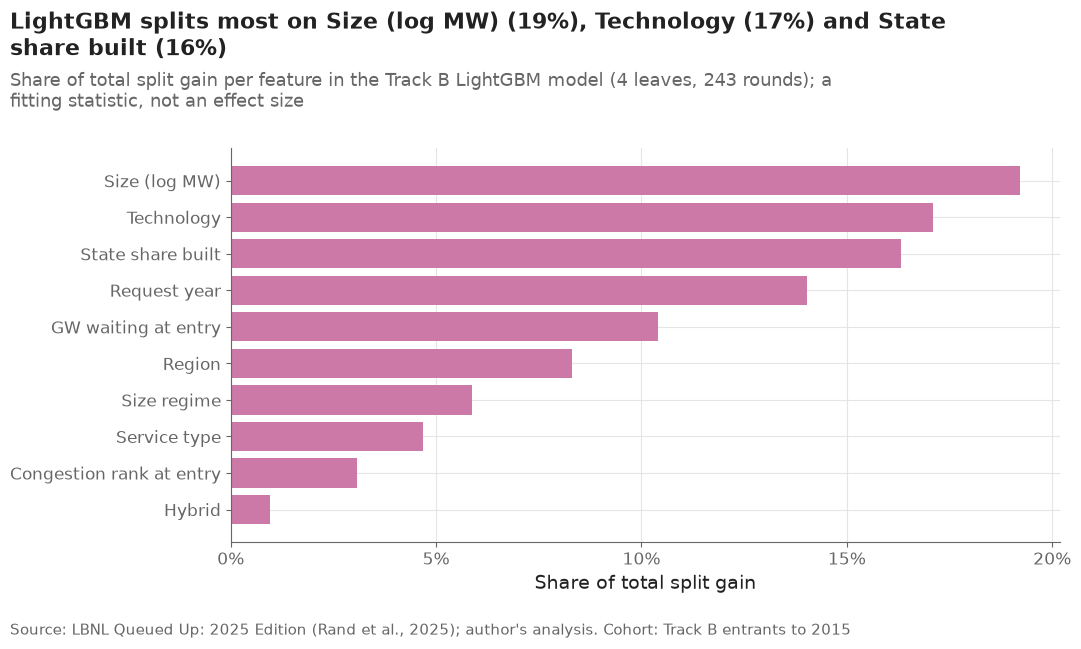

log_mw               0.192
tech                 0.171
state_rate           0.163
q_year               0.140
log_congestion_gw    0.104
region               0.083
size_regime          0.059
service              0.047
congestion_rank      0.031
hybrid               0.009
dtype: float64

In [13]:
gain = lgbm.feature_importance("gain")
importance = pd.Series(gain / gain.sum(), index=track_b.lgbm_design(tune_enc.iloc[:5]).columns).sort_values()
importance.to_csv(paths.RESULTS / "trackB_lgbm_importance.csv", header=["gain_share"])
NAMES = {"region": "Region", "tech": "Technology", "size_regime": "Size regime", "service": "Service type", "hybrid": "Hybrid",
         "log_mw": "Size (log MW)", "q_year": "Request year", "log_congestion_gw": "GW waiting at entry",
         "congestion_rank": "Congestion rank at entry", "state_rate": "State share built"}
fig, ax = plt.subplots()
ax.barh(range(len(importance)), importance.to_numpy(), color=MODEL_COLORS["lgbm"])
ax.set_yticks(range(len(importance)), [NAMES[f] for f in importance.index])
ax.set_xticks(np.arange(0, importance.max() + 0.05, 0.05))
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of total split gain")
top = importance.sort_values(ascending=False)
plots.finish(fig,
             f"LightGBM splits most on {NAMES[top.index[0]]} ({top.iloc[0]:.0%}), {NAMES[top.index[1]]} ({top.iloc[1]:.0%}) and "
             f"{NAMES[top.index[2]]} ({top.iloc[2]:.0%})",
             f"Share of total split gain per feature in the Track B LightGBM model ({LGBM_PARAMS['num_leaves']} leaves, "
             f"{N_ROUNDS} rounds); a fitting statistic, not an effect size",
             "Track B entrants to 2015")
save(fig, "07_11_lgbm_importance", "Split-gain importance of each feature in the Track B LightGBM model.")
plt.show()
top.round(3)

**Reading this.** Across all nine regions, other things equal, ERCOT requests have 3.56× PJM's odds of being built and ISO-NE requests 0.55×; gas has 3.18× solar's odds, "Other" 2.31× and wind 1.57×, offshore wind 0.18×. Size has a steady gradient: under 5 MW 1.33×, then 0.78×, 0.62× and 0.32× for the classes from 100 MW up, against 20–100 MW. A missing service type (0.48×) marks weaker requests. More GW waiting at entry lowers the odds (0.663 per log unit), as Johnston et al. (2023) argue. One sign differs from Track A: each later request year raises the odds slightly (1.034 per year). That is the selection of the first section showing through — later cohorts keep fewer of their slow, still-waiting requests — and a reason not to read Track B coefficients as causal. Solar+Battery's 10.3× (interval 5.2–21.4) rests on few resolved hybrids. LightGBM leans on size (19.2% of the gain), technology (17.1%), the state's share built (16.3%) and request year (14.0%), with region at 8.3%.

## 7. Predictions for the 2016 and 2017 cohorts

Final predictions: the fits on entrants to 2015, raw and through the isotonic
maps fitted on 2016. For 2016 requests the calibrated values are the
cross-fitted ones (section 4). The base rate for 2017 uses entrants to 2016.
The observed outcome is carried for notebook 08; nothing below summarises
it for the 2017 cohort.

In [14]:
raw_test = {"logit": logit.predict_proba(track_b.logit_design(test_enc))[:, 1], "lgbm": lgbm.predict(track_b.lgbm_design(test_enc))}
pieces = []
for split, frame, raw, base, cal in [
        ("validation", valid, raw_valid, valid_preds["baseline"], {m: valid_preds[f"{m}_cal"] for m in raw_valid}),
        ("test", test, raw_test, track_b.base_rates(pd.concat([tune, valid]), test)["rate"].to_numpy(),
         {m: maps[m].predict(raw_test[m]) for m in raw_test})]:
    pieces.append(pd.DataFrame({"project_key": frame["project_key"].astype(str), "region": frame["region"].astype(str),
                                "q_year": frame["q_year"].astype(int), "split": split, "baseline": base,
                                "logit": raw["logit"], "lgbm": raw["lgbm"], "logit_cal": cal["logit"], "lgbm_cal": cal["lgbm"],
                                "built": frame["built"].astype(int)}))
predictions_b = pd.concat(pieces, ignore_index=True)
out_file = paths.DATA_PROCESSED / "predictions_trackB.parquet"
predictions_b.to_parquet(out_file, index=False)
print(f"{out_file.name}: {len(predictions_b):,} rows, {out_file.stat().st_size / 1e6:.2f} MB")
print("highest calibrated P(built), 2017 cohort:", predictions_b.loc[predictions_b["split"] == "test", ["logit_cal", "lgbm_cal"]].max().round(3).to_dict())
test_b = predictions_b[predictions_b["split"] == "test"]
test_b.groupby("region")[["baseline", "logit", "lgbm", "logit_cal", "lgbm_cal"]].mean().reindex(REGIONS).round(3)

predictions_trackB.parquet: 2,980 rows, 0.08 MB
highest calibrated P(built), 2017 cohort: {'logit_cal': 0.441, 'lgbm_cal': 0.402}


,baseline,logit,lgbm,logit_cal,lgbm_cal
region,,,,,
ERCOT,0.262,0.262,0.304,0.220,0.269
PJM,0.248,0.318,0.260,0.264,0.249
CAISO,0.218,0.270,0.308,0.224,0.291
MISO,0.160,0.200,0.229,0.179,0.230
SPP,0.167,0.132,0.176,0.120,0.171
NYISO,0.203,0.174,0.158,0.172,0.141
ISO-NE,0.334,0.252,0.229,0.212,0.221
West,0.189,0.176,0.160,0.147,0.145
Southeast,0.072,0.136,0.160,0.136,0.131


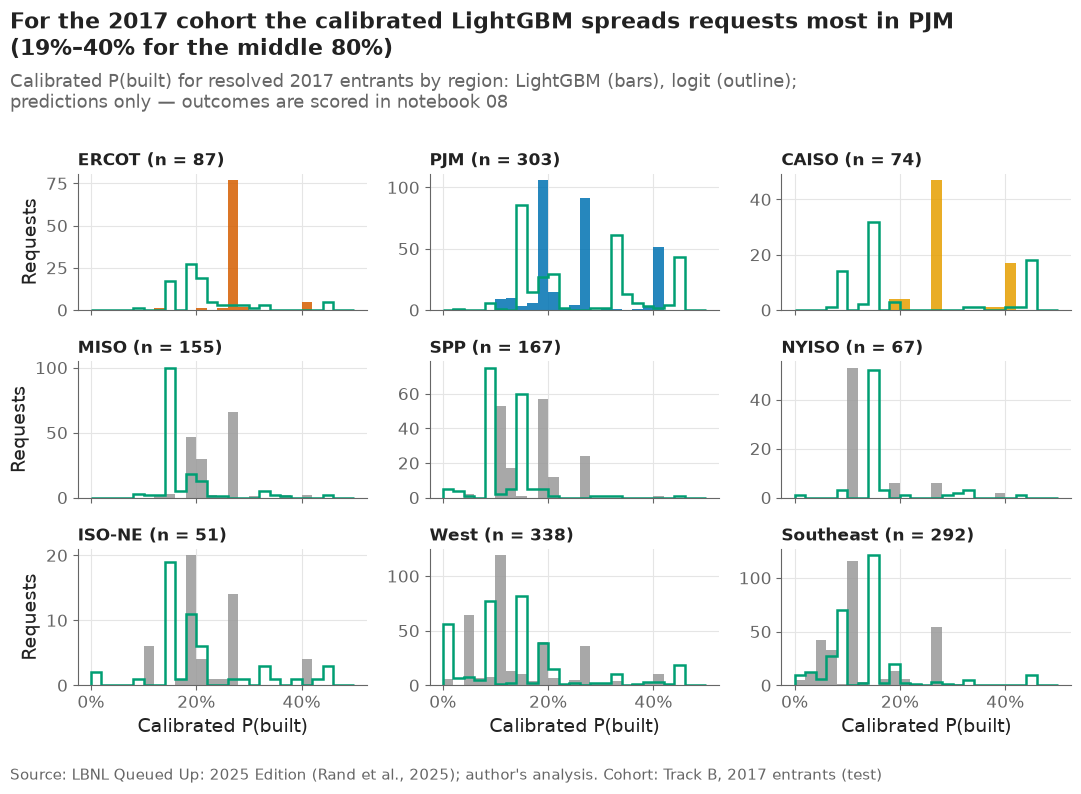

,0.1,0.9
region,,
ERCOT,0.262,0.262
PJM,0.192,0.402
CAISO,0.220,0.402
MISO,0.192,0.262
SPP,0.113,0.262
NYISO,0.113,0.262
ISO-NE,0.114,0.262
West,0.058,0.262
Southeast,0.058,0.262


In [15]:
fig, axes = plt.subplots(3, 3, sharex=True, figsize=(11, 8))
bins = np.linspace(0, 0.5, 26)
for ax, region in zip(axes.flat, REGIONS):
    part = test_b[test_b["region"] == region]
    ax.hist(part["lgbm_cal"], bins=bins, color=region_color(region), alpha=0.85)
    ax.hist(part["logit_cal"], bins=bins, histtype="step", color=MODEL_COLORS["logit"], linewidth=1.8)
    ax.set_title(f"{region} (n = {len(part)})", fontsize=12)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
for ax in axes[-1]:
    ax.set_xlabel("Calibrated P(built)")
for ax in axes[:, 0]:
    ax.set_ylabel("Requests")
spread = test_b.groupby("region")["lgbm_cal"].quantile([0.1, 0.9]).unstack().reindex(REGIONS)
plots.finish(fig,
             f"For the 2017 cohort the calibrated LightGBM spreads requests most in "
             f"{(spread[0.9] - spread[0.1]).idxmax()} ({spread.loc[(spread[0.9] - spread[0.1]).idxmax(), 0.1]:.0%}–"
             f"{spread.loc[(spread[0.9] - spread[0.1]).idxmax(), 0.9]:.0%} for the middle 80%)",
             "Calibrated P(built) for resolved 2017 entrants by region: LightGBM (bars), logit (outline); predictions only — "
             "outcomes are scored in notebook 08",
             "Track B, 2017 entrants (test)")
save(fig, "07_12_test_predictions", "Distribution of calibrated P(built) for the 2017 test cohort by region.")
plt.show()
spread.round(3)

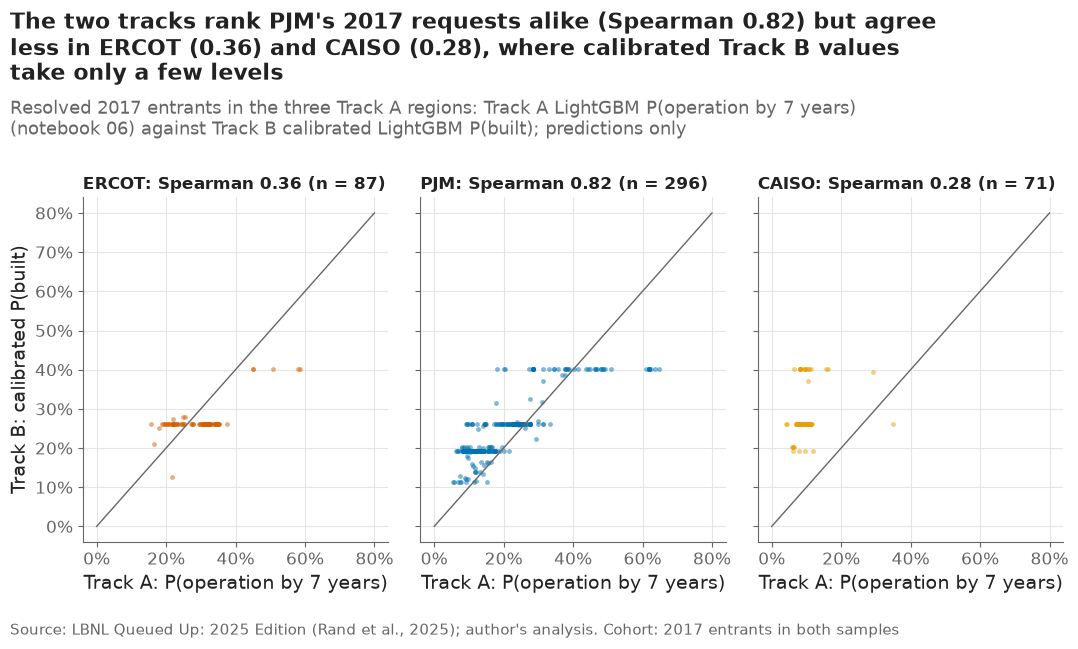

,n,spearman
ERCOT,87.0,0.36
PJM,296.0,0.82
CAISO,71.0,0.28


In [16]:
track_a_pred = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackA.parquet")
track_a_7 = track_a_pred[(track_a_pred["horizon"] == 7) & (track_a_pred["q_year"] == 2017)]
both = test_b.merge(track_a_7[["project_key", "dt_lgbm", "dt_logit"]], on="project_key")
fig, axes = plt.subplots(1, 3, sharex=True, sharey=True)
agreement = {}
for ax, region in zip(axes, config.TRACK_A_REGIONS):
    part = both[both["region"] == region]
    ax.scatter(part["dt_lgbm"], part["lgbm_cal"], s=12, alpha=0.5, color=region_color(region), linewidths=0)
    ax.plot([0, 0.8], [0, 0.8], color=plots.MUTED, linewidth=1)
    agreement[region] = {"n": len(part), "spearman": part[["dt_lgbm", "lgbm_cal"]].corr(method="spearman").iloc[0, 1]}
    ax.set_title(f"{region}: Spearman {agreement[region]['spearman']:.2f} (n = {len(part)})", fontsize=12)
    ax.set_xlabel("Track A: P(operation by 7 years)")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Track B: calibrated P(built)")
agreement = pd.DataFrame(agreement).T
plots.finish(fig,
             f"The two tracks rank PJM's 2017 requests alike (Spearman {agreement.loc['PJM', 'spearman']:.2f}) but agree "
             f"less in ERCOT ({agreement.loc['ERCOT', 'spearman']:.2f}) and CAISO ({agreement.loc['CAISO', 'spearman']:.2f}), "
             "where calibrated Track B values take only a few levels",
             "Resolved 2017 entrants in the three Track A regions: Track A LightGBM P(operation by 7 years) (notebook 06) "
             "against Track B calibrated LightGBM P(built); predictions only",
             "2017 entrants in both samples")
save(fig, "07_13_track_a_vs_b", "Track A 7-year P(operation) against Track B P(built) for the shared 2017 requests.")
plt.show()
agreement.round(2)

**Reading this.** Predictions for the 1,446 validation and 1,534 test requests are in `data/processed/predictions_trackB.parquet` (2,980 rows, raw and calibrated, with the base rate). For the 2017 cohort the calibrated LightGBM is highest on average in CAISO (29.1%) and ERCOT (26.9%) and lowest in the Southeast (13.1%), West (14.5%) and NYISO (14.1%). CAISO's value stands out against its training share built (15.1%) and its base rate (21.8%); notebook 08 should check it first. Within regions the calibrated values cluster on a few levels (in ERCOT the middle 80% is a single value, 26.2%; in PJM 19.2–40.2%), the cost of calibration noted above. On the requests the two tracks share, they rank PJM's 2017 entrants alike (Spearman 0.82 between Track A's 7-year probability and Track B's P(built)) but agree much less in ERCOT (0.36) and CAISO (0.28), where Track B's calibrated values take only a few levels.

## 8. Checks

PLAN.md §6 asks that AUC and Brier beat the region × technology base rate
on the 2017 cohort. Scoring the 2017 cohort here would use test outcomes
before notebook 08 has fixed its success criteria, so that check moves to
notebook 08 (decision #29); here the same comparison is made on the 2016
cohort, out of sample for the raw models.

In [17]:
m = metrics.set_index("model")
allowed = {"region", "tech", "size_regime", "service", "hybrid", "log_mw", "q_year", "log_congestion_gw",
           "congestion_rank", "state_rate"}
runtime = time.time() - START
checks = pd.DataFrame([
    ("predictions for every 2016 and 2017 request, all models, within [0, 1]",
     len(predictions_b) == len(valid) + len(test)
     and bool(predictions_b[["baseline", "logit", "lgbm", "logit_cal", "lgbm_cal"]].apply(lambda s: s.between(0, 1)).all().all())),
    ("features are entry-time only", set(track_b.lgbm_design(tune_enc.iloc[:5]).columns) == allowed),
    ("2016 cohort: both models' AUC above the base rate's",
     bool(m.loc["logit", "auc"] > m.loc["baseline", "auc"] and m.loc["lgbm", "auc"] > m.loc["baseline", "auc"])),
    ("2016 cohort: both models' Brier score below the base rate's",
     bool(m.loc["logit", "brier"] < m.loc["baseline", "brier"] and m.loc["lgbm", "brier"] < m.loc["baseline", "brier"])),
    ("per-region calibration and leave-one-region-out tables written, failing regions named",
     (paths.RESULTS / "trackB_by_region.csv").exists()),
    ("notebook runs in under 10 minutes", runtime < 600),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "trackB_checks.csv", index=False)
print(f"run time: {runtime / 60:.1f} minutes")
checks[["check", "result"]]

run time: 1.4 minutes


,check,result
0,"predictions for every 2016 and 2017 request, a...",PASS
1,features are entry-time only,PASS
2,2016 cohort: both models' AUC above the base r...,PASS
3,2016 cohort: both models' Brier score below th...,PASS
4,per-region calibration and leave-one-region-ou...,PASS
5,notebook runs in under 10 minutes,PASS


**Reading this.** All six checks pass: complete predictions within [0, 1], entry-time features only, both models above the base rate's AUC and below its Brier score on the 2016 cohort, the per-region and leave-one-region-out tables written with the failing regions named (PJM, MISO and SPP on 2016; eight regions held out), and a run time under 10 minutes. PLAN.md's check on the 2017 cohort is moved to notebook 08 (decision #29), so that no test outcome is looked at before the success criteria are fixed.

## Takeaways

- On the 2016 cohort both Track B models rank requests better than the region × technology base rate (AUC 0.665 and 0.662 vs 0.613); their probabilities are only slightly better (Brier 0.1433 and 0.1438 vs 0.1471, overlapping intervals).
- Calibration fixes the average level (18.3% vs 18.4% observed) but not the overall score, and its steps make the calibrated values coarse; binned isotonic regression stops a handful of requests from setting the top of the map (decision #30).
- Held out, a region's level is missed in 8 of 9 regions (ERCOT worst, most likely through its inflated congestion), while ranking still beats the technology-only benchmark in 8 of 9 — use Track B to rank requests outside the training regions, not as a probability.
- Track B's sample keeps only resolved requests, so later cohorts are tilted to fast outcomes (up to 32.6% of 2016 entrants still waiting); the slight rise in odds with request year (1.034 per year) reflects that selection.
- As in Track A, the later cohort chose small trees over the grouped CV's large ones (decision #27).

**What goes to the report:** 07_05 (2016 metrics) in the evaluation section next to notebook 08's test results; 07_08 and 07_09 for the leave-one-region-out limitation; 07_02 for the resolved-only selection; one sentence on calibration (07_06).